# Лабараторная работа 2. Кластерный анализ методом к-средних (k-means)
Выполнила Кравцова София

**Цель.** Сегментировать потребителей леденцов на основе опроса о причинах потребления леденцов. Ответы на вопросы давались в 5-бальной шкале

**Метод:** кластерный анализ методом к-средних (k-means)

In [49]:
# импортируем библиотеки
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
plt.style.use('ggplot')
import seaborn as sns

from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from sklearn.metrics.pairwise import euclidean_distances

import os

In [50]:
import warnings
from sklearn.exceptions import ConvergenceWarning

# Отключаем UserWarning от sklearn
warnings.filterwarnings('ignore', category=UserWarning, module='sklearn')

In [51]:
PATH = os.path.abspath('Задачи для лабораторной_1-3\\labtask1_lollypops\\Леденцы.dat')
# загружаем данные
df = pd.read_csv(PATH, delimiter=';')

## Подготовка

In [52]:
X = df.copy()

In [53]:
X.head() # смотрим, как выглядят данные

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11
0,4,5,5,5,3,3,3,3,3,3,3
1,5,4,5,5,3,3,3,3,3,3,3
2,5,5,4,5,3,3,3,3,3,3,3
3,5,4,5,5,3,3,3,3,3,3,3
4,4,5,5,5,3,3,3,3,3,3,3


In [54]:
X.info()  # смотрим информацию о датасете, какие типы данных и есть ли пропуски

<class 'pandas.DataFrame'>
RangeIndex: 338 entries, 0 to 337
Data columns (total 11 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   V1      338 non-null    int64
 1   V2      338 non-null    int64
 2   V3      338 non-null    int64
 3   V4      338 non-null    int64
 4   V5      338 non-null    int64
 5   V6      338 non-null    int64
 6   V7      338 non-null    int64
 7   V8      338 non-null    int64
 8   V9      338 non-null    int64
 9   V10     338 non-null    int64
 10  V11     338 non-null    int64
dtypes: int64(11)
memory usage: 29.2 KB


Все ячейки заполнены числовыми значениями, пропущенных ячеек нет

In [55]:
X.describe()

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11
count,338.000000,338.000000,338.000000,338.000000,338.000000,338.000000,338.000000,338.000000,338.000000,338.000000,338.000000
mean,3.544379,3.526627,3.517751,3.411243,3.207101,3.204142,3.254438,3.289941,3.603550,3.550296,3.565089
std,0.955748,0.956410,0.990150,0.992311,0.867314,0.869725,0.844107,0.821784,0.969682,0.927082,0.942042
min,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000
25%,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000
50%,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000
75%,5.000000,5.000000,5.000000,4.000000,3.000000,3.000000,3.000000,3.000000,5.000000,5.000000,5.000000
max,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000


Числовые значения однородны, находятся в диапозоне от 2 до 5, выбросов нет. Стандартизация не нужна

In [56]:
# смотрим количество дубликатов (по всем столбцам) в датасете
print(f"Количество дубликатов: {X.duplicated().sum()}")

# В процентах от общего числа записей
print(f"Доля дубликатов: {X.duplicated().mean() * 100:.2f}%")

Количество дубликатов: 293
Доля дубликатов: 86.69%


In [57]:
# посмотреть строки-дубликаты
duplicates = X[X.duplicated(keep=False)]
display(duplicates.sort_values(by=list(X.columns)))

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11
122,2,2,2,2,2,2,2,3,5,5,5
125,2,2,2,2,2,2,2,3,5,5,5
126,2,2,2,2,2,2,2,3,5,5,5
143,2,2,2,2,2,2,2,3,5,5,5
149,2,2,2,2,2,2,2,3,5,5,5
...,...,...,...,...,...,...,...,...,...,...,...
107,5,5,5,5,3,3,3,3,3,3,3
108,5,5,5,5,3,3,3,3,3,3,3
109,5,5,5,5,3,3,3,3,3,3,3
29,5,5,5,5,3,3,3,3,4,4,4


In [58]:
# сколько уникальных комбинаций среди дубликатов
duplicates = X[X.duplicated(keep=False)]

unique_dup_types = duplicates.drop_duplicates().shape[0]
print(f"Уникальных комбинаций среди дубликатов: {unique_dup_types}")

Уникальных комбинаций среди дубликатов: 31


Учитывая характер данных, такое количество дублирующих строк вполне естественно - люди с одинаковыми предпочтениями одинаково отвечают на вопросы. Такое большое количество дубликатов говорит о существовании нескольктих "типажей", которые хорошо разделятся на кластеры. Об этом же говорит количество уникальных комбинаций среди дубликатов.

Поэтому дубликаты можно оставить как есть

## Определение количества кластеров
### Метод локтя
Чтобы определить количество кластеров, воспользуемся "методом локтя". Для этого считаем внутрикластерную сумму квадратов расстояний от каждой точки до центроида кластера при разном заданном количестве кластеров

In [70]:
inertia = []  # Внутрикластерная сумма квадратов расстояний до центроида
k_range = range(2, 11)

for k in k_range:
    kmeans = KMeans(n_clusters=k, n_init=10, random_state=42)
    kmeans.fit(X)
    inertia.append(kmeans.inertia_)

<function matplotlib.pyplot.show(close=None, block=None)>

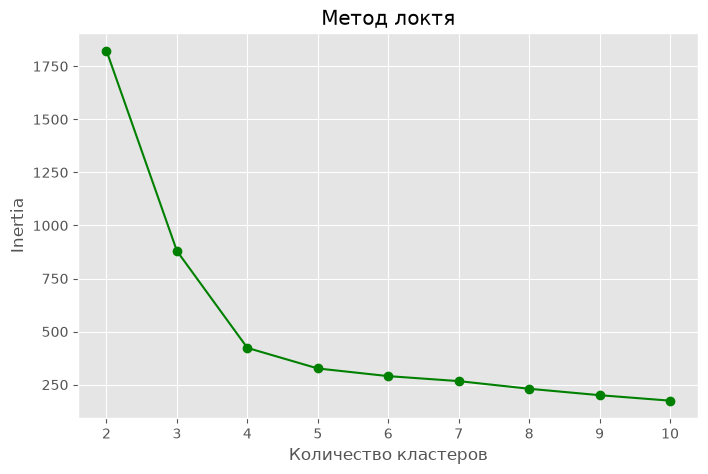

In [71]:
plt.figure(figsize=(8, 5))
plt.plot(k_range, inertia, '-og')
plt.xlabel('Количество кластеров')
plt.ylabel('Inertia')
plt.title('Метод локтя')
plt.xticks(k_range)

plt.show

Inertia - внутрикластерная сумма квадратов расстояний точек до ближайшего к ней центроида. При достижении оптимального количества кластеров должна перестать резко падать. 
По построенному нами графику выбираем k=4

### Силуэт

Чтобы удостовериться в правильности выбранного числа кластеров, посчитаем силуэт для различного числа кластеров

Силуэт (Silhouette score) - метрика, которая оценивает, насколько хорошо объекты сгруппированы в кластеры. Она показывает, насколько каждый объект «похож» на свой кластер по сравнению с соседними.

Для каждой точки вычисляется коэффициент силуэта по формуле:
s = (b - a) / max(a, b)

Где:

- a — среднее расстояние от точки до всех других точек внутри её собственного кластера (мера сплочённости).
- b — среднее расстояние от точки до всех точек ближайшего соседнего кластера (мера разделимости).

Значение силуэта находится в диапазоне от -1 до 1:
- Близко к 1: точка находится далеко от соседнего кластера и близко к своему. Кластеризация хорошая.
- Около 0: точка находится на границе между кластерами.
- Близко к -1: точка, вероятно, отнесена не к тому кластеру.

Общий силуэт для всей кластеризации — это среднее значение по всем точкам

In [72]:
silhouette_scores = []
#k_range = range(2, 11)

for k in k_range:
    # обучаем kmeans
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X)
    
    # Считаем силуэт
    score = silhouette_score(X, labels)
    silhouette_scores.append(score)
    print(f"k={k}: silhouette = {score:.3f}")

k=2: silhouette = 0.455
k=3: silhouette = 0.614
k=4: silhouette = 0.727
k=5: silhouette = 0.702
k=6: silhouette = 0.704
k=7: silhouette = 0.626
k=8: silhouette = 0.631
k=9: silhouette = 0.657
k=10: silhouette = 0.672


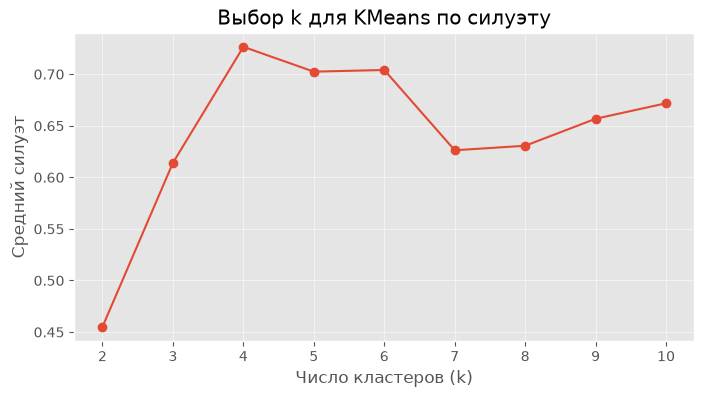


Оптимальное k = 4


In [73]:
# визуализация
plt.figure(figsize=(8, 4))
plt.plot(k_range, silhouette_scores, marker='o')
plt.xlabel('Число кластеров (k)')
plt.ylabel('Средний силуэт')
plt.title('Выбор k для KMeans по силуэту')
plt.grid(True, alpha=0.5)
plt.show()

best_k = k_range[silhouette_scores.index(max(silhouette_scores))]
print(f"\nОптимальное k = {best_k}")

## Кластеризация

In [63]:
k = 4

kmeans = KMeans(n_clusters=k, n_init=10, random_state=42)
labels = kmeans.fit_predict(X)  # сразу получаем метки получившихся кластеров

In [64]:
# добавляем метки кластеров в датафрейм
X_labeled = X.copy()
X_labeled['cluster'] = labels

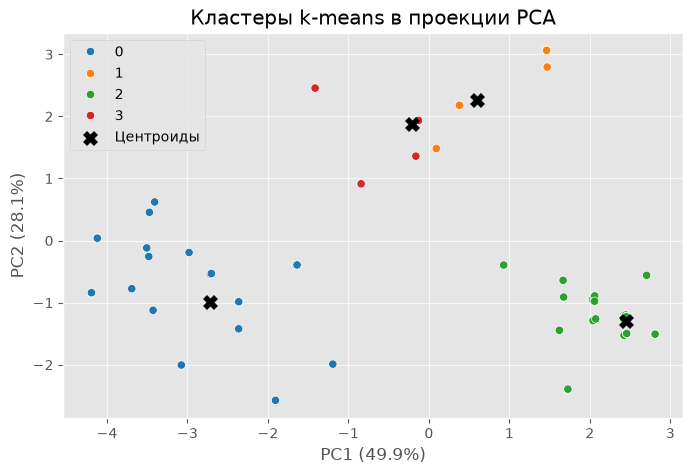

In [65]:
# визуализируем получившиеся кластеры с помощью PCA (Principal Component Analysis)

# сжимаем 11 признаков до 2-х компонент
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X)

plt.figure(figsize=(8, 5))
sns.scatterplot(
    x=X_pca[:, 0], y=X_pca[:, 1],
    hue=labels,
    palette='tab10'
)
# отмечаем центроиды
centers_pca = pca.transform(kmeans.cluster_centers_)
plt.scatter(
    centers_pca[:, 0], centers_pca[:, 1],
    marker='X', s=100, c='black', edgecolor='black',
    label='Центроиды', zorder=5
)
plt.xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.1%})')
plt.ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.1%})')
plt.title(f'Кластеры k-means в проекции PCA')
plt.legend()
plt.grid(alpha=0.7)
plt.show()

In [66]:
# считаем среднее расстояние до центроида для каждого кластера
all_distances = euclidean_distances(X, kmeans.cluster_centers_)  # расстояние от каждой точки до всех центроидов
distances_to_own_centroids = all_distances[np.arange(len(X)), kmeans.labels_]  # выбираем расстояние до своего центроида

for cluster_id in range(kmeans.n_clusters):
    mask = kmeans.labels_ == cluster_id
    mean_dist = distances_to_own_centroids[mask].mean()
    n_points = mask.sum()
    print(f"Кластер {cluster_id}: n ={n_points:4d}, "
          f"среднее расстояние = {mean_dist:.3f}, ")

Кластер 0: n = 108, среднее расстояние = 1.385, 
Кластер 1: n =  61, среднее расстояние = 0.830, 
Кластер 2: n = 110, среднее расстояние = 0.849, 
Кластер 3: n =  59, среднее расстояние = 0.375, 


## Интерпретация кластеров

In [67]:
X_labeled.groupby('cluster').size().sort_values(ascending=False)

cluster
2    110
0    108
1     61
3     59
dtype: int64

In [74]:
X_labeled['cluster'].value_counts(normalize=True).mul(100).round(2)  # считаем соотношение кластеров в процентах

cluster
2    32.54
0    31.95
1    18.05
3    17.46
Name: proportion, dtype: float64

In [68]:
X_labeled.groupby('cluster').mean()

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11
cluster,,,,,,,,,,,
0,2.824074,2.833333,2.768519,2.620370,2.611111,2.583333,2.750000,2.916667,4.953704,4.814815,4.861111
1,3.000000,3.000000,3.000000,3.000000,4.852459,4.852459,3.000000,2.918033,2.754098,2.754098,2.754098
2,4.845455,4.800000,4.836364,4.681818,3.036364,3.036364,3.000000,2.990909,3.072727,3.045455,3.045455
3,3.000000,2.966102,2.966102,2.915254,2.915254,2.949153,4.915254,4.915254,3.000000,3.000000,3.000000


Для интерпретации смотрим на то, в каких вопросах (V1-V11) среднее стремится к 5. Это будет означать, что респонденты в основном указывали 5 в ответах на эти вопросы и, следовательно, именно этим можно охарактеризовать причины потребления леденцов для респондентов, попавших в этот кластер

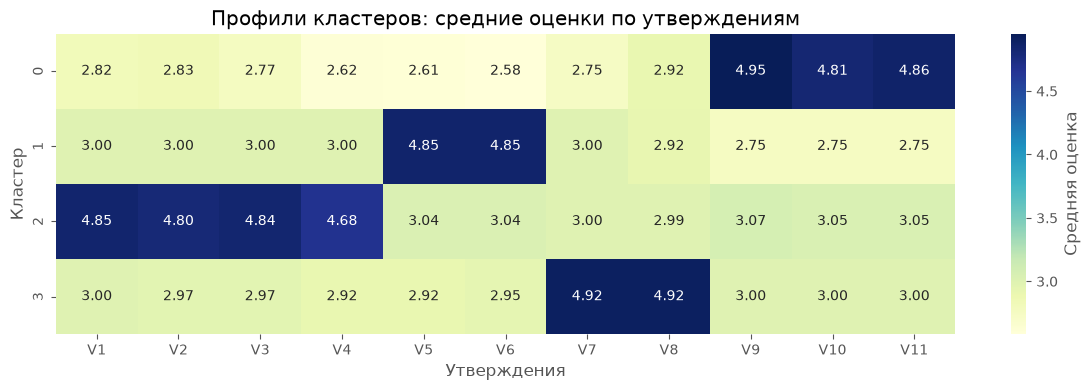

In [69]:
profile = X_labeled.groupby('cluster')[['V1','V2','V3','V4','V5',
                                        'V6','V7','V8','V9','V10','V11']].mean()

plt.figure(figsize=(12, 4))
sns.heatmap(profile, annot=True, fmt='.2f', cmap='YlGnBu',
            cbar_kws={'label': 'Средняя оценка'})
plt.title('Профили кластеров: средние оценки по утверждениям')
plt.xlabel('Утверждения')
plt.ylabel('Кластер')
plt.tight_layout()
plt.show()

### Вопросы, на которые отвечали респонденты (оценка по 5-бальной шкале)
- V1: Я потребляю леденцы, чтобы освежить дыхание
- V2: Я потребляю леденцы, чтобы чувствовать себя увереннее
- V3: Я потребляю леденцы, чтобы освежить полость рта
- V4: Я потребляю леденцы, чтобы избавиться от неприятного вкуса во рту
- V5: Я потребляю леденцы как заменитель других кондитерских изделий
- V6: Я потребляю леденцы, когда мне хочется чего-нибудь сладкого
- V7: Леденцы помогают мне сконцентрироваться
- V8: Я потребляю леденцы, чтобы отвлечься на несколько минут и подумать
- V9: Я потребляю леденцы для того, чтобы облегчить боль в горле
- V10: Я потребляю леденцы для того, чтобы избавиться от заложенности носа
- V11: Я потребляю леденцы для улучшения самочувствия
### Какие вопросы респонденты, причисленные к каждому кластеру, оценивали одинаково высоко:
- кластер 1: V9-11
- кластер 2: V1-4
- кластер 3: V7-8
- кластер 4: V5-6
### Группы респондентов по цели потребления леденцов:
1. леденцы как способ избавиться от неприятного запаха изо рта и почувствовать себя увереннее (кластер 2, 110 записей)
2. леденцы как способ улучшить физическое самочувствие (боль в горле, заложенность носа) (кластер 1, 108 записей)
3. леденцы как источник сахара (кластер 4, 61 запись)
4. леденцы как способ сконцентрироваться (кластер 3, 59 записей)

## Вывод
На основе данных было выделено 4 кластера, характеризующих причины потребления респондентами леденцов: гигиенически-имиджевый, лечебно-функциональный, вкусовой и психологический с процентным соотношением  32.54, 31.95, 18.05 и 17.46 соответственно.
Данные разделились на разные по размеру, но довольно однородные и сбалансированные кластеры. Больше половины (64.49%) приходится на 2 кластера, остаток записей на оставшиеся 2. Кластеры хорошо разделимы по содержательным блокам утверждений: каждый кластер имеет выраженный «пик» на своей группе мотивов и заметно ниже оценивает остальные, что подтверждает осмысленность разбиения.

Кластер 1 — «лечебно-функциональный» (108 респондентов, 31.95%). Респонденты этого кластера одинаково высоко оценили утверждения V9–V11, отражающие облегчение симптомов (боль в горле, заложенность носа) и улучшение самочувствия. Для них леденцы — прежде всего средство физической помощи организму, близкое к аптечному продукту. Остальные мотивы (гедонистические, имиджевые, психологические) выражены слабее. Практически это означает акцент на функциональных ингредиентах (мёд, травы, ментол), доверительной коммуникации и аптечном канале продаж.

Кластер 2 — «гигиенически-имиджевый» (110 респондентов, 32.54%). Наибольшие оценки получены по V1–V4: освежение дыхания и полости рта, устранение неприятного вкуса и связанная с этим уверенность в себе. Это самый крупный кластер, и в нём гигиенический мотив неразрывно связан с социальным самоощущением — леденцы выступают инструментом «быть в порядке» в общении. Для этой группы релевантны акцент на свежесть, мятные/цитрусовые вкусы, компактная упаковка «на ходу» и выкладка у кассы.

Кластер 3 — «психологический» (59 респондентов, 17.46%). Высокие оценки по V7–V8 (концентрация и возможность отвлечься, «переключиться» на несколько минут). Это самый малочисленный кластер; леденцы здесь выполняют роль ритуала-паузы в работе или учёбе. Коммуникация для этой группы — «микроперерыв», концентрация, небольшие порции, офисный/учебный контекст.

Кластер 4 — «вкусовой» (61 респондент, 18.05%). Пик по V5–V6: леденцы как заменитель других кондитерских изделий и способ удовлетворить тягу к сладкому. Мотивация гедоническая, связанная со вкусом и удовольствием, а не с функцией или имиджем. Здесь работают вкусовое разнообразие, новинки, яркая упаковка и импульсные покупки.

Таким образом, потребление леденцов неоднородно и распадается на четыре качественно различных мотива: функционально-лечебный, гигиено-имиджевый, психологический (переключение/концентрация) и вкусовой (гедонический). Два первых кластера охватывают около двух третей выборки (64.49%) и отражают «утилитарное» потребление (польза для здоровья и социального самоощущения), тогда как два оставшихся (35.51%) ближе к эмоциональному и ритуальному потреблению. Кластеры различаются преимущественно по содержательным блокам утверждений, а не по случайным колебаниям оценок, что делает интерпретацию устойчивой.